{'username': 'rr', 'greeting': 'hirr', 'output': 'hirr111'}


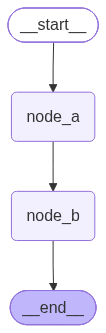

In [4]:
from langgraph.graph import StateGraph,START,END
from typing import  TypedDict
from IPython.display import display

class OverAllState(TypedDict):
    username:str
    greeting:str
    output:str



def node_a(state:OverAllState)->OverAllState:
    return {
        "greeting":"hi"+state["username"]
    }

def node_b(state:OverAllState)->OverAllState:
    return {
        "output":state["greeting"]+"111"
    }

builder=StateGraph(state_schema=OverAllState)
builder.add_node("node_a",node_a)
builder.add_node("node_b",node_b)
builder.add_edge(START,"node_a")
builder.add_edge("node_a","node_b")
builder.add_edge("node_b",END)

graph=builder.compile()
res=graph.invoke({"username":"rr"})
print(res)
display(graph)

{'username': 'rr', 'greeting': 'hirr', 'output': 'hirr111'}


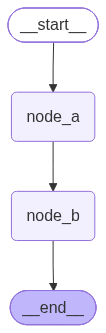

In [6]:
from langgraph.graph import StateGraph,START,END
from typing import  TypedDict
from IPython.display import display

class OverAllState(TypedDict):
    username:str
    greeting:str
    output:str



def node_a(state:OverAllState)->OverAllState:
    return {
        "greeting":"hi"+state["username"]
    }

def node_b(state:OverAllState)->OverAllState:
    return {
        "output":state["greeting"]+"111"
    }

builder=StateGraph(state_schema=OverAllState)
#builder.add_node("node_a",node_a)
#builder.add_node("node_b",node_b)
builder.add_edge(START,"node_a")
builder.add_sequence([node_a,node_b])
builder.add_edge("node_b",END)

graph=builder.compile()
res=graph.invoke({"username":"rr"})
print(res)
display(graph)

{'username': 'rr', 'greeting': 'hirr', 'output': 'hirr111'}


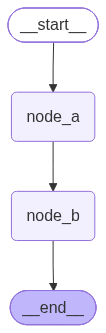

In [7]:
from langgraph.graph import StateGraph,START,END
from typing import  TypedDict
from IPython.display import display

class OverAllState(TypedDict):
    username:str
    greeting:str
    output:str



def node_a(state:OverAllState)->OverAllState:
    return {
        "greeting":"hi"+state["username"]
    }

def node_b(state:OverAllState)->OverAllState:
    return {
        "output":state["greeting"]+"111"
    }

builder=StateGraph(state_schema=OverAllState)
#builder.add_node("node_a",node_a)
#builder.add_node("node_b",node_b)
builder.add_edge(START,"node_a")
builder.add_sequence([node_a,node_b])
#builder.add_edge("node_b",END)

graph=builder.compile()
res=graph.invoke({"username":"rr"})
print(res)
display(graph)

{
    'topic': '猫咪',
    'poem': 
'《猫》\n轻身一跃上窗台，碧眼晶莹映日开。\n忽向花间扑蝴蝶，又随春色入帘来。\n\n赏析：这首作品以猫咪为主角，通过“轻
身一跃”、“碧眼晶莹”等生动描绘，展现其灵动与晶莹剔透的形象。后两句“忽向花间扑蝴蝶，又随春色入帘来”，巧妙捕捉猫咪扑蝶
的瞬间，并融入春色，既表现其活泼天性，又暗含春意盎然的意境，语言清新自然，饶有趣味。',
    'joke': 
'一只猫和主人一起去餐厅吃饭。服务员问主人：“您要点什么？”主人说：“我要一份牛排。”服务员又问：“那您的猫呢？”主人说：
“它跟我吃一样的就行。”\n\n过了一会儿，服务员端来一份牛排放在猫面前，猫闻了闻，抬头对服务员说：“喵。”\n\n服务员愣了
一下，问主人：“它是不是不满意？”\n\n主人叹了口气：“不，它是在说——‘没叉子我怎么吃？’”'
}

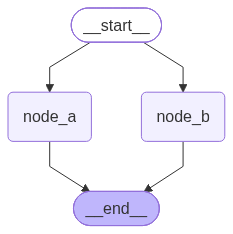

In [9]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from rich import print as rprint
from dotenv import  load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
rprint(res)

from IPython.display import display

display(graph)

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'poem': '《布偶狗》\n彩线金针绣锦绒，玲珑乖巧肖形同。\n不吠不咬常缄口，朝夕伴余欢乐中。\n\n赏析：这首作品以布偶狗为题材，通过“彩线金针”与“玲珑乖巧”的描绘，生动展现了其精巧可爱的手工特质。后两句“不吠不咬常缄口，朝夕伴余欢乐中”，既点出其静默无言的布偶属性，又抒发了它作为玩伴带来的持久欢愉，语言凝练而意趣盎然。', 'content_type': '诗'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'joke': '有一天，一只布偶狗被主人带去宠物店洗澡。\n\n店员问：“这狗怎么一动不动？”\n\n主人说：“因为它是我缝的。”\n\n店员笑了：“那你还带它来洗？”\n\n主人一本正经：“掉毛了，总得洗洗吧。”\n\n店员看了看它身上掉出来的一团棉花，说：“行，那要吹干吗？”\n\n主人摇头：“不用，它怕热——一吹就缩水。”'}


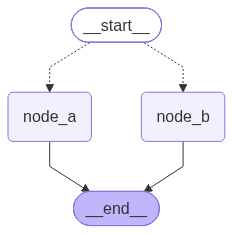

In [11]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from rich import print as rprint
from dotenv import  load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    content_type: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def router(state:OverAllState) -> Literal["node_a","node_b"] :
    if"诗" in state["content_type"]:
        return "node_a"
    else:
        return "node_b"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(START,router)

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)


from IPython.display import display

display(graph)

============================== -> poem_res <- ==============================


{
    'topic': '布偶狗',
    'poem': 
'《布偶狗》\n绒团伏枕眼眯缝，竖耳垂毛态自慵。\n忽作腾扑旋风起，却衔拖鞋入怀中。\n\n注：我的创作思路是抓住布偶狗静动
转换的瞬间趣味。首句以“绒团”写其柔软形态，“眼眯缝”拟人化描摹慵懒神态；次句“竖耳垂毛”突出布偶特征。后两句笔锋陡转，
用“腾扑旋风”的夸张动态打破静谧，最终落于“衔拖鞋”的顽皮日常，通过反差凸显布偶狗既憨态可掬又活泼机敏的特质。',
    'content_type': '诗',
    'ci_poem': 
'《鹧鸪天·布偶狗》\n绒耳初缝线脚斜，玻璃珠子作眸华。\n盘中坐卧憨态可掬，枕上依偎梦爪牙。\n衔布骨，系绸花，儿童争抱
笑无邪。\n夜深怕染风霜色，收向檀箱深处藏。\n\n注：我的创作思路是围绕布偶狗这一主题，通过细腻的描绘展现其可爱与陪伴
。上阕以缝制细节入手，“绒耳”“玻璃珠子”凸显手工质感，后以“憨态”“梦爪牙”拟人化其静态中的生动。下阕转写与儿童的互动，“
衔布骨”“系绸花”具象化玩耍场景，末句以珍藏细节收束，暗含对纯真年代的怜惜。全词借物抒情，语言凝练而意象丰富。'
}

============================== -> joke_res <- ==============================


{
    'topic': '布偶狗',
    'content_type': '笑话',
    'joke': '## 
一只布偶狗的自白\n\n我家养了一只布偶狗，就是那种毛茸茸、软绵绵、眼睛像玻璃珠的玩具狗。我妈特别喜欢它，每天晚上都要
抱着它看电视，还给它起了个名字叫“旺财”。\n\n有一天我实在忍不住了，问我妈：“妈，你天天抱着个假狗，有意思吗？”\n\n我
妈头也不抬：“你懂什么，人家旺财可聪明了。”\n\n我说：“它就是个布偶，连‘坐下’都听不懂。”\n\n我妈立刻对着布偶狗喊：“旺
财，坐下！”然后一把把它按在沙发上，“你看，多听话。”\n\n我：“……”\n\n过了几天，我下班回家，发现我妈正对着布偶狗训话：
“旺财！你又把沙发咬坏了！再这样我揍你！”然后举起拖鞋对着布偶狗比划了一下。\n\n我实在看不下去了：“妈，那是你自己昨天
不小心用剪刀划的……”\n\n我妈瞪了我一眼：“闭嘴，旺财在反省呢。”然后把布偶狗翻了个面，让它面壁思过。\n\n最绝的是昨天晚
上，我听见我妈在客厅嘀咕：“旺财啊，你最近是不是胖了？来，上秤称称。”然后真把布偶狗放上了体重秤，还认真地读了个数：“
哎哟，三斤二两，得减肥了。”\n\n今天早上，我妈突然惊慌失措地跑来：“不好了！旺财不呼吸了！”\n\n我无奈地看了一眼那个本
来就没有呼吸功能的布偶：“妈，它从来就不呼吸。”\n\n我妈愣了两秒，然后一把抱住布偶狗，深情地说：“没关系，妈妈给你做人
工呼吸。”\n\n我：“……”\n\n现在我很担心，等哪天我妈发现旺财其实是我小时候扔掉的毛绒玩具，她可能会先给我做人工呼吸。',
    'ci_poem': 
'《临江仙·布偶狗》\n软绒绒团憨态，圆溜溜眼温柔。\n伴人左右解烦忧。\n晨昏廊下卧，星月枕边留。\n虽未闻声吠影，却能知
冷知愁。\n贴心长伴胜朋俦。\n春风拂尾处，摇落一庭秋。\n\n注：我的创作思路是抓住布偶狗“静默陪伴”的核心特质进行意象化
表达。上阕通过“软绒绒”“圆溜溜”等叠词摹写其形态，以“晨昏廊下卧，星月枕边留”展现全天候的守候。下阕转写其精神慰藉功能
，“知冷知愁”赋予拟人化灵性，尾句“摇落一庭秋”用通感手法，将静态布偶与季节流转相勾连，暗喻时光沉淀中的恒久温情。'
}

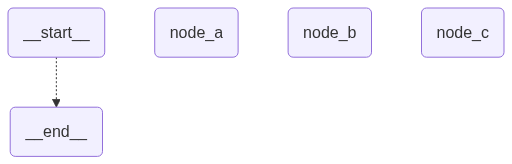

In [18]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal,Sequence
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from rich import print as rprint
from dotenv import  load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    content_type: str
    joke: str
    ci_poem:str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state:OverAllState) -> Sequence[Literal["node_a","node_b","node_c"]] :
    if"诗" in state["content_type"]:
        return ["node_a","node_c"]
    return ["node_b","node_c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START,router)

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
rprint(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
rprint(joke_res)


from IPython.display import display

display(graph)

============================== -> poem_res <- ==============================


{
    'topic': '布偶狗',
    'poem': 
'《布偶狗》\n绒身纸骨笑眸晶，静卧窗台似守卫。\n忽有外人来探访，摇头摆尾示欢迎。\n\n赏析：这首作品以布偶狗为题材，通
过“绒身纸骨”与“笑眸晶”的对比，生动描绘了其材质与神态。后两句运用拟人手法，赋予布偶狗守卫的职责与迎客的热情，既展现
了其作为装饰品的静态美，又通过“摇头摆尾”的动态想象，传达出活泼趣味，整体语言简练而意象鲜明。',
    'content_type': '诗',
    'ci_poem': 
'《鹧鸪天·布偶狗》\n绒耳垂云尾曳风，琉璃瞳映画堂东。\n偎人欲语声先软，绕膝承欢态自慵。\n衔花影，扑帘栊，韶光叼住不
教松。\n童心未许轻分付，只向春衫袖底逢。\n\n注：我的创作思路是抓住布偶狗柔软温顺的形态与活泼灵动的瞬间。上阕以“绒耳
垂云”“琉璃瞳”写其静美，下阕用“衔花影”“扑帘栊”摄其动态，结句“童心未许轻分付”暗合布偶狗作为玩伴却保有独立天性的特质，
使物象与情韵相映成趣。'
}

============================== -> joke_res <- ==============================


{
    'topic': '布偶狗',
    'content_type': '笑话',
    'joke': '## 
布偶狗\n\n我妈养了只布偶猫，天天跟我炫耀：“你看这毛多软，这眼睛多蓝，像不像个小公主？”\n\n我实在受不了了，就买了只
布偶狗回来。\n\n我妈一看就炸了：“你疯了吧？这明明是只狗！”\n\n“对啊，”我理直气壮，“布偶狗。”\n\n“哪来的布偶狗？布偶
是猫的品种！”\n\n我把狗抱起来怼到她面前：“你自己看——毛够不够软？眼睛够不够大？是不是一脸无辜？”\n\n我妈凑近端详了半
天：“……确实。”\n\n“而且它比猫强多了。”\n\n“强在哪？”\n\n“你叫它名字，它真会过来。”\n\n我妈当场试了试：“布偶！过来！
”\n\n狗摇着尾巴就跑来了。\n\n我妈沉默了。\n\n过了一会儿，我的布偶猫慢悠悠地从她脚边路过，我妈鬼使神差地喊了句：“布
偶，过来！”\n\n猫头都没回，屁股一扭，走了。\n\n“看见没？”我拍拍我妈肩膀，“你的布偶翻你白眼，我的布偶翻肚皮。知道什
么叫布偶了吧？——布做的偶人才听话，你那只是真祖宗。”',
    'ci_poem': 
'《鹧鸪天·布偶狗》\n绒耳垂云软系腰，琉璃眼嵌两粒娇。\n扯来星月缝衣袂，偷得蟾光补髻髫。\n身可可，尾摇摇。闲庭信步胜
花猫。\n偶然扑蝶纱帘后，却把春风绊一跤。\n\n注：我的创作思路是借鉴李清照婉约词风，以拟人化手法描摹布偶狗的灵动可爱
。上阕用“绒耳垂云”“琉璃眼”等意象表现其材质与神态，下阕通过“扑蝶纱帘”的细节呈现童趣。末句“绊春风一跤”以夸张笔法，赋
予布偶狗活泼的生命力，暗合宋词尚趣的传统。'
}

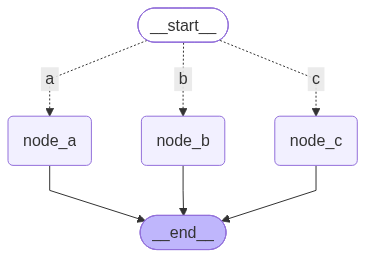

In [19]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal,Sequence
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from rich import print as rprint
from dotenv import  load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    content_type: str
    joke: str
    ci_poem:str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state:OverAllState) -> Sequence[Literal["a","b","c"]] :
    if"诗" in state["content_type"]:
        return ["a","c"]
    return ["b","c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START,router,path_map={
    "a":"node_a",
    "b":"node_b",
    "c":"node_c"
})

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
rprint(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
rprint(joke_res)


from IPython.display import display

display(graph)

2026-11-23 20:35:22.836 | INFO     | __main__:audit_node:40 - 任务节点全部执行完毕，诗 已生成，笑话 已生成


{'topic': '布偶狗', 'poem': '《布偶狗》\n绒团乖巧卧窗台，晶眼凝神待主来。\n忽闻门响翻身起，摇头摆尾扑入怀。\n\n注：我的创作思路是抓住布偶狗作为玩具与情感伴侣的双重特性。首句“绒团”既写材质又传神态，“晶眼”拟人化展现期待。后两句通过“忽闻门响”的转折，以动态描写打破静态画面，用“摇头摆尾”的拟态动作与“扑入怀”的亲密接触，生动展现布偶狗作为情感寄托物的温暖特质。', 'joke': '## 布偶狗的笑话\n\n小明过生日，妈妈送了他一只布偶狗。这只布偶狗做得特别逼真，毛茸茸的，眼睛还会发光。\n\n小明特别喜欢，天天搂着睡觉。过了几天，他发现布偶狗掉毛掉得厉害，客厅地板上全是狗毛。他纳闷地问他妈：“妈，这布偶狗是不是质量不行啊？怎么老掉毛？”\n\n他妈头也不抬地说：“别瞎说，那是你爸昨天把真狗牵回来，跟布偶狗放一块儿分不清了。你抱错了，那是隔壁王大爷家的萨摩耶。”\n\n小明一愣：“那……那我搂着睡了好几天的是真狗？”\n\n他妈点点头：“可不，那狗现在天天往咱家跑，赶都赶不走。你爸正跟王大爷商量买狗的事呢。”\n\n小明低头看了看怀里的“布偶狗”，布偶狗也抬头看了他一眼，然后舔了他一脸口水。\n\n这时候他爸从外面进来，手里举着一张纸条：“王大爷说了，狗可以留下，但得按布偶狗的价儿给钱——他说这狗会装死，算‘智能玩具’，得加钱。”\n\n小明：“……所以这几天我到底是在跟狗睡还是跟玩具睡？”\n\n他爸拍了拍他的肩膀：“儿子，别纠结了。主要是你王大爷那狗太会演了——你搂它的时候，它真的一动不动，比布偶还像布偶。你妈都夸它‘演技好，该拿奥斯卡’。”\n\n他妈在厨房补了一句：“就是运费有点贵——王大爷说这狗每天自己跑回去吃三顿饭，来回跑了三趟，得按打车算。”'}


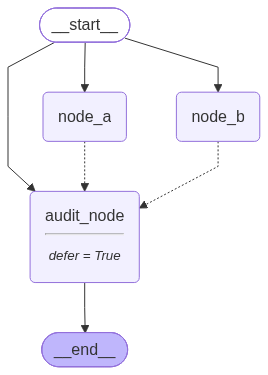

In [20]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from loguru import logger

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点全部执行完毕，诗 {'已生成' if state['poem'] else '未生成'}，笑话 {'已生成' if state['joke'] else '未生成'}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("audit_node", audit_node, defer=True)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
print(res)

from IPython.display import display

display(graph)

{
    'poem': '## 
《布偶狗》\n\n我梦见布偶狗在吠叫，\n在空无一人的街角，\n它的绒毛沾满灰尘，\n它的眼珠不再闪耀。\n\n我梦见布偶狗在奔
跑，\n穿过被遗忘的走廊，\n它的耳朵缺了一角，\n它的尾巴拖在地上。\n\n我梦见布偶狗在哭，\n像孩子弄丢了礼物，\n它的线
头松散开来，\n它的棉絮飘向远处。\n\n我梦见布偶狗在笑，\n向着那轮苍白的月，\n它的影子越来越长，\n它的歌声越来越远。\
n\n我梦见布偶狗死了，\n在清晨六点的站台，\n它的口袋装满沙砾，\n它的胸口落满尘埃。\n\n可它还在那里坐着，\n在空无一人
的街角，\n当所有钟声都沉默，\n它只是坐着，不吠叫。',
    'ci_poem': 
'《鹧鸪天·布偶狗》\n绒耳初温偎绣榻，琉璃双眼映星灯。\n尾摇犹带云间态，爪落偏随絮影轻。\n衔锦线，扑流萤，几回惊梦却
无声。\n谁将巧思缝憨态，留取春风掌上擎。\n\n注：我的创作思路是围绕布偶狗“静中藏动”的特质展开。上阕以“绒耳”“琉璃眼”
等意象刻画其静卧之态，而“尾摇云间”“爪落絮影”则暗写其灵动。下阕通过衔线扑萤的细节，在童趣中透出拟人化的情致，结句“春
风掌上擎”既呼应布偶的掌中玩物属性，又以春风喻其温暖陪伴，使全词在柔婉中见余韵。',
    'joke': 
'好的，这是一个关于“布偶狗”的笑话：\n\n从前有一只布偶狗，它特别喜欢冲人摇尾巴。有一天它遇到了一只真狗，真狗问它：“
你天天这么摇，不累吗？”\n\n布偶狗说：“不累啊，我里面是棉花，摇断了也不疼。”\n\n真狗很羡慕，回家把自己的尾巴也拆了换
成棉花。结果第二天它哭着来找布偶狗：“我摇了一晚上，尾巴是没断……但我棉花全甩出来了，现在屁股漏风，一走路就‘噗噗’响！
”\n\n布偶狗淡定地说：“你傻呀，我是布偶狗，你是真狗——你摇尾巴靠的是肌肉，我摇尾巴靠的是……主人拎着我抖！”'
}

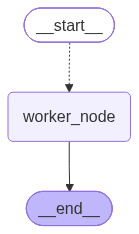

In [24]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from rich import print as rprint
from dotenv import load_dotenv
load_dotenv(override=True)

CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatDeepSeek(
    model = "deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]

    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

def router(state: InputState) -> Sequence[Send]:
    prompt = "请生成关于 {} 的 {}"
    english2chinese = {
        "poem": "一首诗",
        "ci_poem": "一首词",
        "joke": "一个笑话"
    }

    topic = state["topic"]

    return [Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": prompt.format(topic, english2chinese[content_type]),
            }
        ) for content_type in CONTENT_TYPES
    ]

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"]
)
builder.add_edge("worker_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
rprint(res)

from IPython.display import display
display(graph)

============================== -> poem <- ==============================
{'topic': '布偶猫', 'poem': '《布偶猫》\n蓝瞳玉雪卧芸窗，尾扫流云影亦双。\n忽作娇啼蹭肩软，却垂长耳入梦乡。\n\n注：我的创作思路是抓住布偶猫的外貌特征与温顺性格。首句“蓝瞳玉雪”写其湛蓝眼睛与雪白毛发，“卧芸窗”显其慵懒之态。次句“尾扫流云”以动写静，暗合布偶猫长尾飘拂如云。第三句“娇啼蹭肩”通过声音与动作表现其亲人特性，结句“垂耳入梦”则勾勒出猫儿酣睡的可爱画面。全诗通过动静结合的手法，展现布偶猫的优雅与温柔。', 'content_type': 'poem'}
============================== -> joke <- ==============================
{'topic': '布偶猫', 'joke': '一只布偶猫走进酒吧，对酒保说：“给我来一杯牛奶。”\n\n酒保说：“对不起，我们这里不招待猫。”\n\n布偶猫很委屈：“可是我真的好渴……”\n\n酒保叹了口气：“好吧，但你别指望我给你好脸色看——毕竟我是个**冷**酒吧，而你是个**布偶**，咱俩谁也别嫌谁**面瘫**。”', 'content_type': 'joke'}
============================== -> illegal <- ==============================
{'topic': '布偶猫', 'content_type': 'illegal'}
{'poem': '## 《布偶狗》\n\n我梦见布偶狗在吠叫，\n在空无一人的街角，\n它的绒毛沾满灰尘，\n它的眼珠不再闪耀。\n\n我梦见布偶狗在奔跑，\n穿过被遗忘的走廊，\n它的耳朵缺了一角，\n它的尾巴拖在地上。\n\n我梦见布偶狗在哭，\n像孩子弄丢了礼物，\n它的线头松散开来，\n它的棉絮飘向远处。\n\n我梦见布偶狗在笑，\n向着那轮苍白的月，\n它的影子越来越长，\n它的歌声越来越远。\n\n我梦见布偶狗死了，\n在清晨六点的站台，\n它的口袋装满沙砾，\n它的胸口落满尘埃。\n\n可它还在那里坐着，\n在空无一人的街角，\n当所有钟声都沉默，\n它只是坐着，

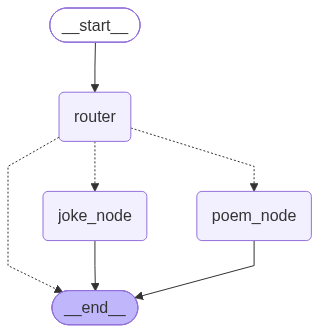

In [26]:
from typing import TypedDict,Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langgraph.types import Command


from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    content_type:Literal["poem","joke"]

def router(state:OverAllState) -> Command[Literal["poem_node","joke_node",END]]:
    content_type=state["content_type"]
    if content_type == "poem":
        return Command(
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command(
            goto="joke_node"
        )
    return Command(
        goto=END
    )

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content

    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content

    return {
        "joke": joke
    }



builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

print(res)

from IPython.display import display

display(graph)

2026-11-23 20:57:07.378 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-11-23 20:57:07.381 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-11-23 20:57:07.389 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-11-23 20:57:07.393 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-11-23 20:57:07.394 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


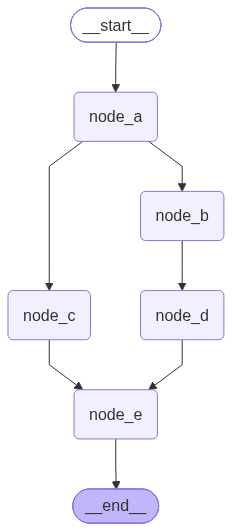

In [27]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
builder.add_edge(["node_c", "node_d"], "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

2026-11-23 20:59:48.261 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-11-23 20:59:48.264 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-11-23 20:59:48.268 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-11-23 20:59:48.273 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-11-23 20:59:48.273 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-11-23 20:59:48.276 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


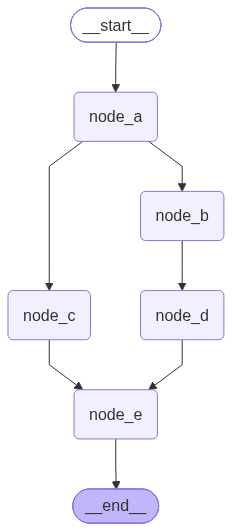

In [28]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")

# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)